In [3]:
import matplotlib
_RcParams = type(matplotlib.rcParams)          # parche del Jupyter de Dataproc, como en clase
if not hasattr(_RcParams, "_get"):
    _RcParams._get = _RcParams.get
import matplotlib.pyplot as plt
import pandas as pd
from pyspark.sql import SparkSession, functions as F

In [4]:
spark = SparkSession.builder.appName("01b_bronze_eda").getOrCreate()
spark.conf.set("spark.sql.session.timeZone", "UTC")

BUCKET = "taxis-chicago-grandes-datos-506301"
taxi = spark.read.parquet(f"gs://{BUCKET}/bronze/taxi_trips")
weather = spark.read.option("mergeSchema", "true").parquet(f"gs://{BUCKET}/bronze/weather")

26/10/02 20:21:27 INFO SparkEnv: Registering MapOutputTracker
26/10/02 20:21:27 INFO SparkEnv: Registering BlockManagerMaster
26/10/02 20:21:27 INFO SparkEnv: Registering BlockManagerMasterHeartbeat
26/10/02 20:21:27 INFO SparkEnv: Registering OutputCommitCoordinator
26/10/02 20:21:36 WARN YarnSchedulerBackend$YarnSchedulerEndpoint: Attempted to request executors before the AM has registered!


In [3]:
total_rows = taxi.count()          # rápido: Parquet lo responde con metadatos
print(f"Filas: {total_rows:,}")

Filas: 212,046,737


In [4]:
# --- Celda 2: tamaño, rango de fechas y duplicados (la más pesada) ---
key_counts = taxi.groupBy("unique_key").count()
dup = key_counts.agg(
    F.count("*").alias("distinct_keys"),
    F.sum((F.col("count") > 1).cast("int")).alias("repeated_keys"),
    F.max("count").alias("max_copies"),
).first()
print(f"Llaves distintas: {dup['distinct_keys']:,}")
print(f"Filas duplicadas: {total_rows - dup['distinct_keys']:,} ({(total_rows - dup['distinct_keys']) / total_rows:.1%})")
print(f"Llaves repetidas: {dup['repeated_keys']:,} | máximo de copias de una llave: {dup['max_copies']}")
taxi.agg(F.min("trip_start_timestamp").alias("first_trip"),
         F.max("trip_start_timestamp").alias("last_trip")).show(truncate=False)

Llaves distintas: 169,511,471
Filas duplicadas: 42,535,266 (20.1%)
Llaves repetidas: 42,535,266 | máximo de copias de una llave: 2


+-------------------+-------------------+
|first_trip         |last_trip          |
+-------------------+-------------------+
|2013-01-01 00:00:00|2023-12-31 23:45:00|
+-------------------+-------------------+



In [5]:
# --- Celda 3: ¿los duplicados son copias idénticas? Ejemplo con un solo día ---
one_day = taxi.filter(F.to_date("trip_start_timestamp") == "2023-06-01")
sample_keys = one_day.groupBy("unique_key").count().filter("count > 1").limit(3).select("unique_key")
one_day.join(sample_keys, "unique_key").orderBy("unique_key").show(6, truncate=20)

+----------+-------+--------------------+------------------+------------+----------+-------------------+--------------------+---------------------+----------------------+----+----+-----+------+----------+------------+-------+---------------+----------------+---------------+----------------+-----------------+----------------+
|unique_key|taxi_id|trip_start_timestamp|trip_end_timestamp|trip_seconds|trip_miles|pickup_census_tract|dropoff_census_tract|pickup_community_area|dropoff_community_area|fare|tips|tolls|extras|trip_total|payment_type|company|pickup_latitude|pickup_longitude|pickup_location|dropoff_latitude|dropoff_longitude|dropoff_location|
+----------+-------+--------------------+------------------+------------+----------+-------------------+--------------------+---------------------+----------------------+----+----+-----+------+----------+------------+-------+---------------+----------------+---------------+----------------+-----------------+----------------+
+----------+-------

In [6]:
# --- Celda 4: nulos por columna ---
nulls = taxi.select([F.sum(F.col(c).isNull().cast("int")).alias(c) for c in taxi.columns]).first().asDict()
null_table = (pd.DataFrame({"nulls": pd.Series(nulls)})
              .assign(pct=lambda d: (d["nulls"] / total_rows * 100).round(2))
              .sort_values("pct", ascending=False))
print(null_table)

                           nulls    pct
dropoff_census_tract    81657274  38.51
pickup_census_tract     80353476  37.89
company                 31877310  15.03
dropoff_community_area  28357452  13.37
dropoff_location        27819194  13.12
dropoff_longitude       27819194  13.12
dropoff_latitude        27819194  13.12
tolls                   27321533  12.88
pickup_community_area   23414082  11.04
pickup_location         23388574  11.03
pickup_longitude        23388573  11.03
pickup_latitude         23388573  11.03
trip_seconds             1349425   0.64
trip_total                 21544   0.01
tips                       21544   0.01
extras                     21544   0.01
fare                       21544   0.01
trip_end_timestamp         21537   0.01
payment_type                   0   0.00
taxi_id                        0   0.00
trip_miles                  2564   0.00
trip_start_timestamp           0   0.00
unique_key                     0   0.00


In [7]:
# --- Celda 5: valores inválidos, uno por cada regla de silver ---
components = sum(F.coalesce(F.col(c), F.lit(0.0)) for c in ["fare", "tips", "tolls", "extras"])
checks = taxi.agg(
    F.sum((F.col("trip_seconds") < 60).cast("int")).alias("seconds_under_60"),
    F.sum((F.col("trip_seconds") > 4 * 3600).cast("int")).alias("seconds_over_4h"),
    F.sum((F.col("trip_miles") == 0).cast("int")).alias("miles_zero"),
    F.sum((F.col("fare") <= 0).cast("int")).alias("fare_zero_or_negative"),
    F.sum((F.col("fare") > 500).cast("int")).alias("fare_over_500"),
    F.sum((F.col("trip_end_timestamp") < F.col("trip_start_timestamp")).cast("int")).alias("end_before_start"),
    F.sum((F.abs(F.col("trip_total") - components) > 1).cast("int")).alias("total_mismatch_over_1usd"),
).first().asDict()
check_table = (pd.DataFrame({"rows": pd.Series(checks)})
               .assign(pct=lambda d: (d["rows"] / total_rows * 100).round(2)))
print(check_table)

                              rows    pct
seconds_under_60          14221213   6.71
seconds_over_4h             104270   0.05
miles_zero                50375657  23.76
fare_zero_or_negative       308521   0.15
fare_over_500                24704   0.01
end_before_start            458437   0.22
total_mismatch_over_1usd    221018   0.10


In [8]:
# --- Celda 6: distribuciones, para sustentar los umbrales (sobre una muestra del 5%) ---
numeric = ["trip_seconds", "trip_miles", "fare", "trip_total"]
probs = [0.01, 0.25, 0.5, 0.75, 0.99, 0.999]
quantiles = taxi.sample(False, 0.05, seed=42).approxQuantile(numeric, probs, 0.001)
print(pd.DataFrame(quantiles, index=numeric, columns=[f"p{p * 100:g}" for p in probs]))

                p1    p25     p50     p75      p99     p99.9
trip_seconds  0.00  327.0  550.00  986.00  3663.00  86399.00
trip_miles    0.00    0.1    1.10    3.10    20.40   3080.00
fare          3.25    6.0    8.25   14.60    52.76   9725.85
trip_total    3.25    7.0    9.85   16.65    68.70   9755.22


    year     trips  pct_no_pickup_area  pct_miles_zero
0   2013  35438190                13.4            35.7
1   2014  39523076                 9.5            22.8
2   2015  23604750                13.8            28.8
3   2016  22707263                19.5            24.7
4   2017  19582632                11.8            22.8
5   2018  19206406                 7.2            21.7
6   2019  24994550                 6.7            16.1
7   2020   5894649                 7.2            16.0
8   2021   7767266                 7.8            14.9
9   2022   6793419                 8.1            12.6
10  2023   6534536                 3.8            10.5


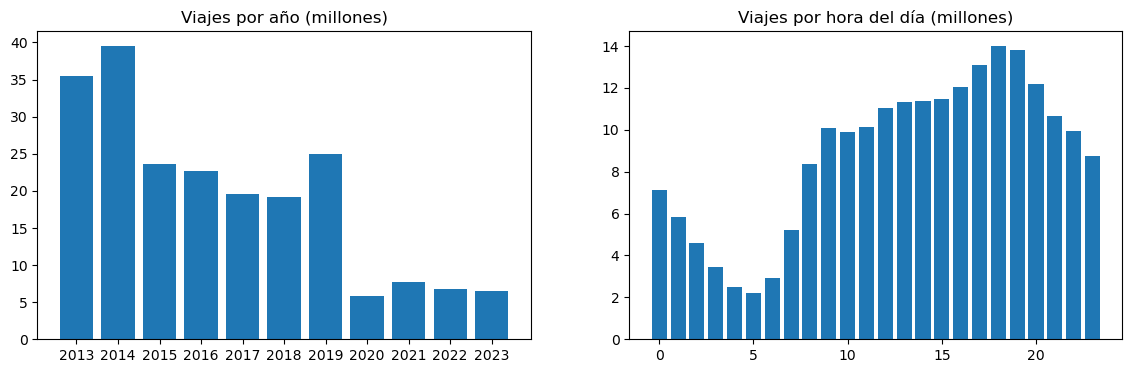

In [9]:
# --- Celda 7: evolución por año y perfil por hora ---
by_year = (taxi.groupBy(F.year("trip_start_timestamp").alias("year"))
           .agg(F.count("*").alias("trips"),
                F.round(F.avg(F.col("pickup_community_area").isNull().cast("int")) * 100, 1).alias("pct_no_pickup_area"),
                F.round(F.avg((F.col("trip_miles") == 0).cast("int")) * 100, 1).alias("pct_miles_zero"))
           .orderBy("year").toPandas())
by_hour = (taxi.groupBy(F.hour("trip_start_timestamp").alias("hour")).count()
           .orderBy("hour").toPandas())
print(by_year)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar(by_year["year"].astype(str), by_year["trips"] / 1e6)
axes[0].set_title("Viajes por año (millones)")
axes[1].bar(by_hour["hour"], by_hour["count"] / 1e6)
axes[1].set_title("Viajes por hora del día (millones)")
plt.show()

In [10]:
# --- Celda 8: variables categóricas y zonas ---
(taxi.groupBy("payment_type")
 .agg(F.count("*").alias("trips"),
      F.round(F.avg((F.col("tips") > 0).cast("int")) * 100, 1).alias("pct_with_tip"))
 .orderBy(F.desc("trips")).show(truncate=False))
taxi.groupBy("company").count().orderBy(F.desc("count")).show(10, truncate=False)
taxi.agg(F.min("pickup_community_area").alias("min_area"),
         F.max("pickup_community_area").alias("max_area"),
         F.countDistinct("pickup_community_area").alias("distinct_areas"),
         F.countDistinct("taxi_id").alias("distinct_taxis"),
         F.countDistinct("company").alias("distinct_companies")).show()

+------------+---------+------------+
|payment_type|trips    |pct_with_tip|
+------------+---------+------------+
|Cash        |118525399|0.1         |
|Credit Card |84504255 |94.3        |
|Mobile      |2956310  |93.8        |
|Prcard      |2794601  |6.2         |
|Unknown     |2159339  |4.3         |
|No Charge   |962456   |16.4        |
|Dispute     |115732   |0.2         |
|Pcard       |26488    |6.6         |
|Prepaid     |2112     |0.4         |
|Way2ride    |39       |87.2        |
|Split       |6        |83.3        |
+------------+---------+------------+



+----------------------------------------+--------+
|company                                 |count   |
+----------------------------------------+--------+
|Taxi Affiliation Services               |54160257|
|null                                    |31877310|
|Flash Cab                               |21184193|
|Blue Ribbon Taxi Association Inc.       |13041546|
|Dispatch Taxi Affiliation               |11609291|
|Choice Taxi Association                 |10214202|
|Yellow Cab                              |8576871 |
|Chicago Elite Cab Corp. (Chicago Carriag|5386430 |
|Star North Management LLC               |5218239 |
|Sun Taxi                                |4959719 |
+----------------------------------------+--------+
only showing top 10 rows



+--------+--------+--------------+--------------+------------------+
|min_area|max_area|distinct_areas|distinct_taxis|distinct_companies|
+--------+--------+--------------+--------------+------------------+
|       1|      77|            77|          9737|               176|
+--------+--------+--------------+--------------+------------------+



In [5]:
# --- Celda 3b: ¿las dos copias son idénticas? ¿en qué años están los duplicados? ---
row_hash = F.xxhash64(*taxi.columns)
per_key = (taxi.groupBy("unique_key")
           .agg(F.count("*").alias("copies"),
                F.countDistinct(row_hash).alias("versions"),
                F.min(F.year("trip_start_timestamp")).alias("year")))
(per_key.groupBy("year")
 .agg(F.count("*").alias("distinct_trips"),
      F.sum((F.col("copies") > 1).cast("int")).alias("repeated_keys"),
      F.sum((F.col("versions") > 1).cast("int")).alias("keys_with_different_copies"))
 .orderBy("year").show())

+----+--------------+-------------+--------------------------+
|year|distinct_trips|repeated_keys|keys_with_different_copies|
+----+--------------+-------------+--------------------------+
|2013|      27211394|      8226796|                         0|
|2014|      35184850|      4338226|                         0|
|2015|      23585985|        18765|                         0|
|2016|      20219676|      2487587|                         0|
|2017|      12909221|      6673411|                         0|
|2018|      13219184|      5987222|                         0|
|2019|      16467167|      8527383|                         0|
|2020|       3888831|      2005818|                         0|
|2021|       3947677|      3819589|                         0|
|2022|       6382071|       411348|                         0|
|2023|       6495415|        39121|                         0|
+----+--------------+-------------+--------------------------+



In [11]:
# --- Celda 9: clima ---
STATION = "stn = '725300' AND wban = '94846'"   # aeropuerto O'Hare
print(f"Filas de clima: {weather.count():,}")
print(f"Estaciones distintas: {weather.select('stn', 'wban').distinct().count():,}")
(weather.where(STATION).groupBy("year")
 .agg(F.count("*").alias("days"),
      F.sum((F.col("temp") > 200).cast("int")).alias("temp_missing"),
      F.sum((F.col("prcp") > 99).cast("int")).alias("prcp_missing"),
      F.round(F.min("temp"), 1).alias("min_temp_f"),
      F.round(F.max("temp"), 1).alias("max_temp_f"))
 .orderBy("year").show())

Filas de clima: 45,256,966


Estaciones distintas: 15,683


+----+----+------------+------------+----------+----------+
|year|days|temp_missing|prcp_missing|min_temp_f|max_temp_f|
+----+----+------------+------------+----------+----------+
|2013| 365|           0|           0|       3.6|      86.8|
|2014| 365|           0|           0|      -7.7|      81.9|
|2015| 365|           0|           0|      -2.1|      81.5|
|2016| 366|           0|           0|      -0.6|      84.6|
|2017| 365|           0|           0|       0.4|      85.0|
|2018| 365|           0|           0|      -2.4|      87.1|
|2019| 365|           0|           0|     -15.0|      85.5|
|2020| 366|           0|           1|       6.0|      86.5|
|2021| 365|           0|           0|       0.1|      83.6|
|2022| 365|           0|           0|      -3.9|      88.7|
|2023| 365|           0|           0|       6.3|      90.2|
+----+----+------------+------------+----------+----------+



In [1]:
spark.stop()